# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [ ]:
# Uncomment and run if required
#!pip install transformers torchvision torch accelerate

In [1]:
from transformers import CLIPModel, CLIPProcessor
import torch

clip_model_name = "openai/clip-vit-base-patch32"
clip_model     = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)

# Set model to evaluation mode, as we are not training it
clip_model.eval()

# Check for accelerators
device = "cpu" # Default to CPU
if torch.cuda.is_available():
    device = "cuda" # Use GPU if available
elif torch.backends.mps.is_available():
    device = "mps"

clip_model.to(device)

print(f"Using device: {device}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Using device: cpu


Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [2]:
from torchvision import datasets
from torch.utils.data import DataLoader

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def collate_clip(batch):
    imgs, labels = zip(*batch) # Unzip the batch into images and labels
    proc = clip_processor(images=list(imgs),
                        return_tensors="pt",
                        padding=True) # Process images with CLIPProcessor
    # Send pixel_values to GPU/CPU now; labels stay on CPU for metrics
    return proc["pixel_values"].to(device), torch.tensor(labels)

#test_dataset = # Complete
#test_loader = # Complete
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=collate_clip
)

In [3]:
test_dataset

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test

In [4]:
test_loader

In [5]:
test_loader.batch_size

16

If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

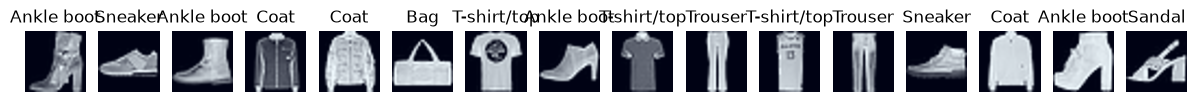

In [6]:
import matplotlib.pyplot as plt

# Display the first batch of images from `test_loader`

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()  # Move images to CPU for plotting
    # Renormalize to [0, 1] for visualization
    images = (images - images.min()) / (images.max() - images.min())
    _, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASS_NAMES[label.item()])
        ax.axis('off')
    plt.show()

show_batch(test_loader)

We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [7]:
def get_text_embeddings(class_names: list[str]) -> torch.Tensor:
    """    Get text embeddings for the given class names using CLIP.
    Args:
        class_names (list[str]): List of class names to encode.
    Returns:
        torch.Tensor: Normalized text embeddings for the class names.
    """
    tokenized = clip_processor(text=class_names,
                               padding=True,
                               return_tensors="pt").to(device)
    
    with torch.no_grad():
        text_embeddings = clip_model.get_text_features(**tokenized)
    text_embeddings = text_embeddings.pooler_output
    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)

    return text_feats

def get_image_embeddings(images: torch.Tensor) -> torch.Tensor:
    """    Get image embeddings for the given images using CLIP.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = clip_model.get_image_features(pixel_values=images)
    image_embeddings = image_embeddings.pooler_output
    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

    return image_feats

In [8]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    cosine_similarity = image_feats @ text_feats.T

    return cosine_similarity.numpy()
##    return cosine_similarity(image_feats.detach().numpy(), text_feats.detach().numpy())

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    #we must find the maximum similarity across the columns (text prompts) for each row (image).
    return np.argmax(similarity, axis=1)

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ ] For each batch of images:
    - [ ] Get image embeddings using the `get_image_embeddings` function.
    - [ ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ ] Save the predictions so that we can build a confusion matrix later.
- [ ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_true, y_pred = [], []
class_embeddings= get_text_embeddings(CLASS_NAMES)

for pixel_values, labels in test_loader:
    image_embeddings= get_image_embeddings(pixel_values)

    similarity = get_cosine_similarity(image_embeddings, class_embeddings)

    predictions = get_predictions(similarity)

# Report the accuracy of the predictions
    accuracy = accuracy_score(labels.cpu().numpy(), predictions)
    print(f"Accuracy: {accuracy:.2f}")

y_true.extend(labels.cpu().numpy())
y_pred.extend(predictions)

accuracy_all = accuracy_score(y_true, y_pred)
print(f"Overall Accuracy: {accuracy_all:.2f}")

# Report the confusion matrix
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()

Accuracy: 0.56
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.62
Accuracy: 0.38
Accuracy: 0.75
Accuracy: 0.38
Accuracy: 0.56
Accuracy: 0.56
Accuracy: 0.31
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.50
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.50
Accuracy: 0.62
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.75
Accuracy: 0.56
Accuracy: 0.69
Accuracy: 0.44
Accuracy: 0.44
Accuracy: 0.81
Accuracy: 0.69
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.69
Accuracy: 0.50
Accuracy: 0.56
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.62
Accuracy: 0.75
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.50
Accuracy: 0.56
Accuracy: 0.56
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.88
Accuracy: 0.75
Accuracy: 0.75
Accuracy: 0.50
Accuracy: 0.50
Accuracy: 0.81
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.81
Accuracy: 0.56
Accuracy: 0.81
Accuracy: 0.69
Accuracy: 0.56
Accuracy: 0.62
Accuracy: 0.50
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.38
Accuracy: 0.44
Accuracy: 

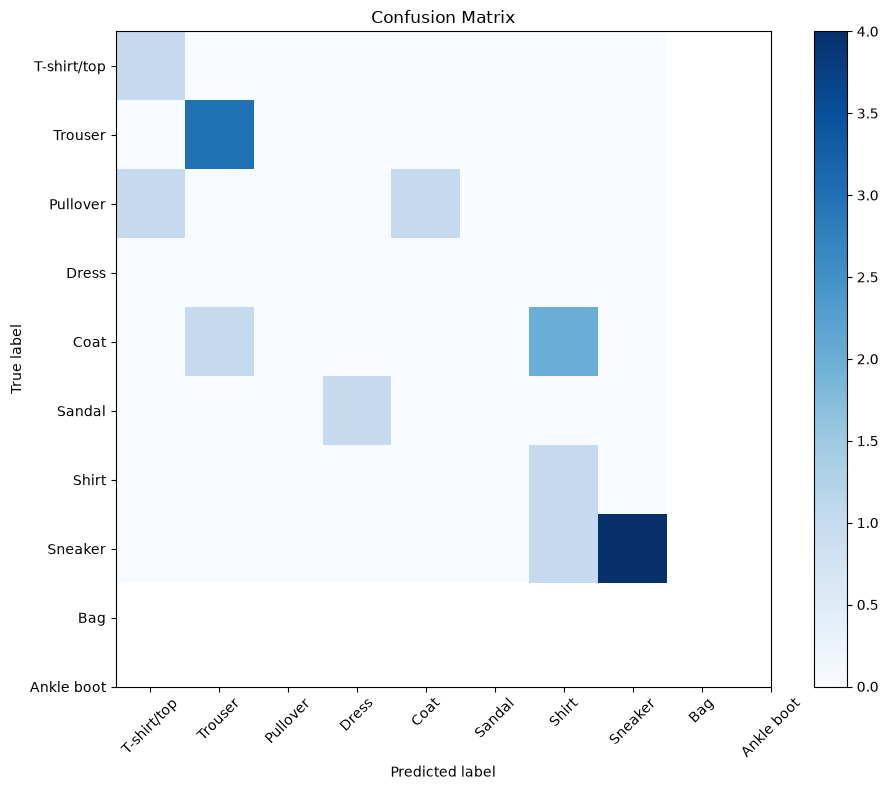

In [10]:
plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)


Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach? 

The zero-shot baseline achieved an accuracy of 56%, which was considerably lower than the CNN models trained in Assignment 1; the final model achieved an accuracy of 89.05% and the baseline model achieved an accuracy of 84.34%. This shows that the CNN models performed better on this clothing classification task.

The main strength of zero-shot classification is that it uses a pretrained model (CLIP) without requiring task-specific training. It is also flexible because it can classify images using text descriptions of the classes.

However, its main weakness is its lower accuracy compared to the CNN models. Its performance also varied across batches, with accuracy ranging from 31% to 88%. The confusion matrix shows that the model sometimes confuses similar categories. For example, some Coat images are misclassified as Shirt or in some cases as Trouser, some Sneaker images as Shirt, and some Sandal images as Dress. Some Pullover images are misclassified as Coat or T-shirt/top. This suggests that the zero-shot model struggles to distinguish between certain clothing categories.

Overall, although zero-shot classification is flexible and requires less training, the CNN models performed better on this dataset.

## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

In [11]:
CLASS_NAMES

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [12]:

improved_prompts = [
    "A photo of a short-sleeved casual T-shirt or sleeveless top, with a simple design and lightweight fabric.",

    "A photo of a pair of long trousers, with two separate legs extending from the waist down to the ankles.",

    "A photo of a long-sleeved knitted sweater or pullover, with thick fabric covering the upper body.",

    "A photo of a one-piece dress, with an upper bodice and a skirt extending down from the waist.",

    "A photo of a long-sleeved outerwear coat, with thick structured fabric, designed to be worn over other clothes.",

    "A photo of an open-toe sandal with exposed parts of the foot and straps, leaving much of the foot uncovered.",

    "A photo of a collared button-up shirt with short or long sleeves, a front button closure and a structured appearance.",

    "A photo of a closed-toe athletic shoe with a rubber sole, covering the foot and designed for walking or sports.",

    "A photo of a handbag or shoulder bag, with a main storage compartment and handles or straps.",

    "A photo of a closed-toe ankle boot with a sturdy sole and an upper section extending above the ankle."
]

In [13]:
improved_text_embeddings = get_text_embeddings(improved_prompts)

Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.44
Accuracy: 0.94
Accuracy: 0.56
Accuracy: 0.56
Accuracy: 0.56
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.56
Accuracy: 0.81
Accuracy: 0.62
Accuracy: 0.62
Accuracy: 0.62
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.81
Accuracy: 0.75
Accuracy: 0.75
Accuracy: 0.56
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.31
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.38
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.88
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.81
Accuracy: 0.62
Accuracy: 0.88
Accuracy: 0.56
Accuracy: 0.69
Accuracy: 0.44
Accuracy: 0.50
Accuracy: 0.25
Accuracy: 0.56
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.81
Accuracy: 0.50
Accuracy: 0.44
Accuracy: 0.69
Accuracy: 0.56
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.69
Accuracy: 0.88
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.88
Accuracy: 0.88
Accuracy: 0.38
Accuracy: 0.62
Accuracy: 0.50
Accuracy: 0.75
Accuracy: 0.69
Accuracy: 0.69
Accuracy: 

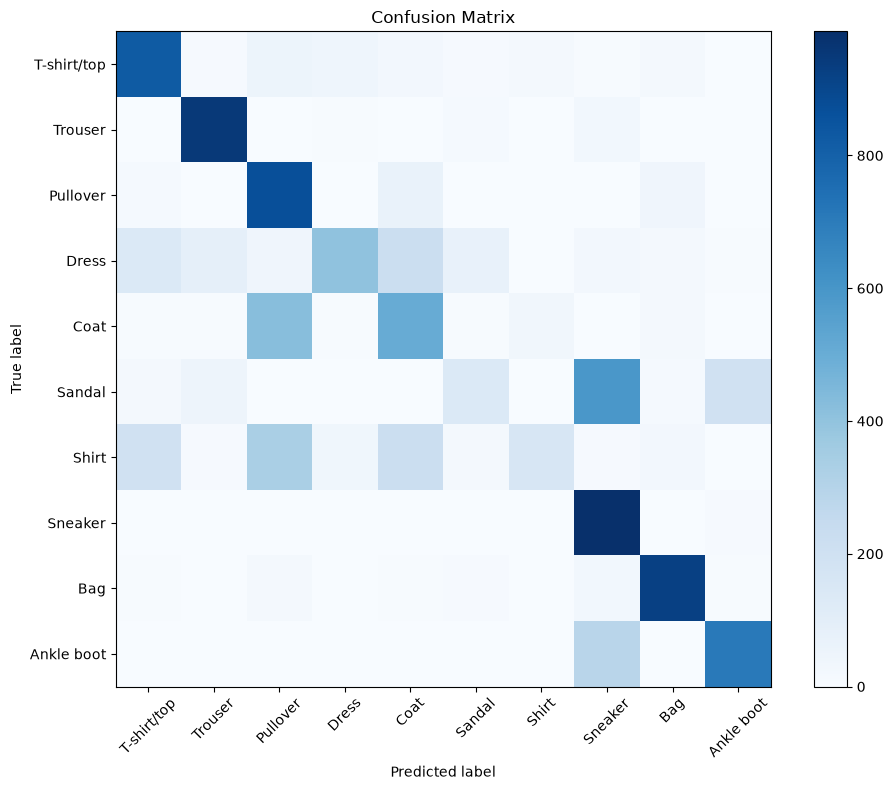

In [14]:
y_true_improved, y_pred_improved = [], []

for pixel_values, labels in test_loader:

    # Get image embeddings
    image_embeddings = get_image_embeddings(pixel_values)

    # Compute cosine similarity using improved text embeddings
    similarity = get_cosine_similarity(
        image_embeddings,
        improved_text_embeddings
    )

    # Get predictions
    predictions = get_predictions(similarity)

    # Report the accuracy of the predictions
    accuracy = accuracy_score(labels.cpu().numpy(), predictions)
    print(f"Accuracy: {accuracy:.2f}")

    # Save labels and predictions
    y_true_improved.extend(labels.cpu().numpy())
    y_pred_improved.extend(predictions)

# Calculate overall accuracy
improved_accuracy = accuracy_score(
    y_true_improved,
    y_pred_improved
)

print(f"Improved Accuracy: {improved_accuracy:.2f}")

# Plot confusion matrix
plot_confusion_matrix(
    y_true_improved,
    y_pred_improved,
    CLASS_NAMES
)

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

Using more descriptive prompts influenced the zero-shot classification performance. The accuracy reached 65% overall, but improved to as high as 94% in some batches. The overall accuracy improved by 9 percentage points compared to the original zero-shot baseline of 56%. This suggests that prompt engineering can improve the model's ability to recognize certain clothing categories, although the results still varied across batches.

The confusion matrix helped identify classes that were frequently misclassified. To address these errors, I created more specific prompts emphasizing visual differences, such as the thick fabric of coats, the knitted appearance of pullovers, the collar and buttons of shirts, and the open-toe design of sandals compared to sneakers.

This experiment showed me that more descriptive prompts can help CLIP distinguish between similar categories, but they do not guarantee consistently higher accuracy. With further experimentation using more specific descriptions and multiple prompts for confusing classes, the performance could potentially improve further. 

## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [ ]:
# Uncomment the following line to install UMAP if you haven't already
# !pip install umap-learn

d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


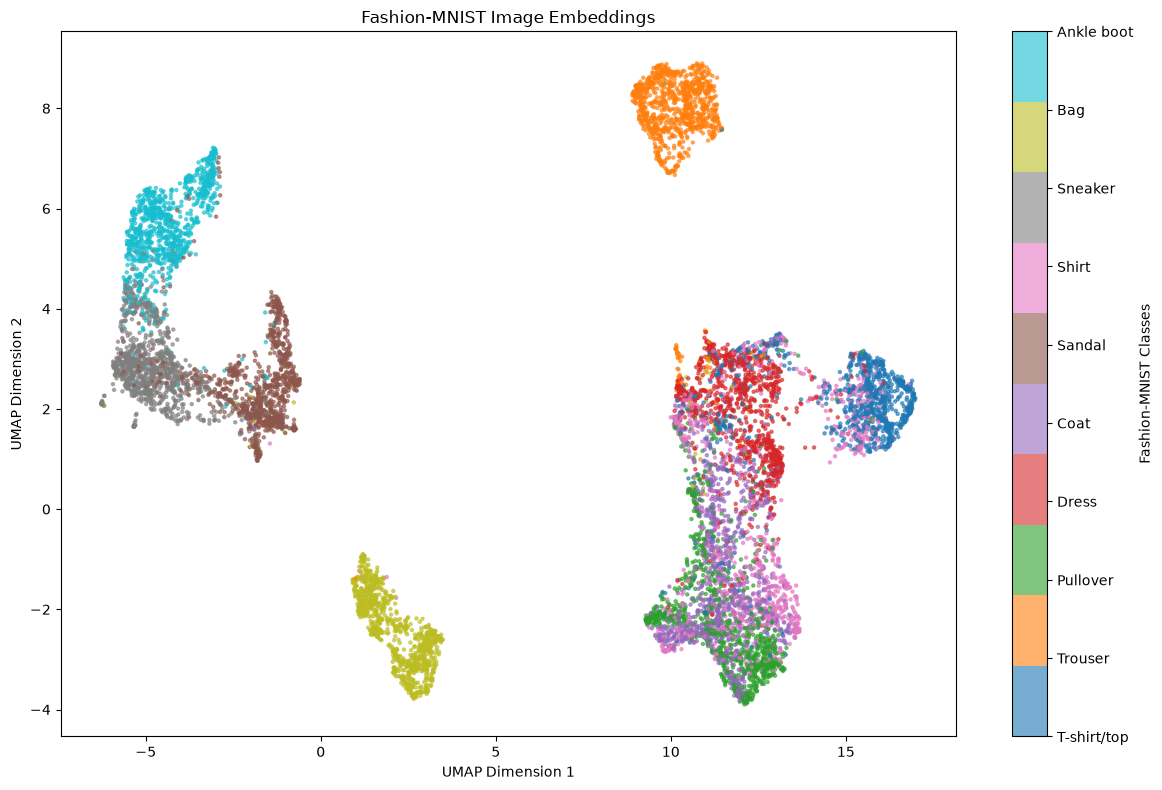

In [15]:
from umap import UMAP

# ------------------------------------------------------------
# 1. Collect image embeddings
# ------------------------------------------------------------
all_img_emb = []
all_labels  = []

for pixel_values, labels in test_loader:
    image_embeddings = get_image_embeddings(pixel_values)
    all_img_emb.append(image_embeddings)
    all_labels.append(labels)   

# Combine all batches
all_img_emb = torch.cat(all_img_emb, dim=0)
all_labels = torch.cat(all_labels, dim=0)

# ------------------------------------------------------------
# 2. Fit UMAP
# ------------------------------------------------------------
UMAP_model = UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
UMAP_embeddings = UMAP_model.fit_transform(all_img_emb.detach().cpu().numpy())


# ------------------------------------------------------------
# 3. Plot coloured by ground-truth label
# ------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 3. Plot UMAP embeddings
# ------------------------------------------------------------
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    UMAP_embeddings[:, 0],
    UMAP_embeddings[:, 1],
    c=all_labels.cpu().numpy(),
    cmap='tab10',
    s=5,
    alpha=0.6
)

# Add colour bar with class names
cbar = plt.colorbar(scatter, ticks=np.arange(10))
cbar.ax.set_yticklabels(CLASS_NAMES)
cbar.set_label('Fashion-MNIST Classes')

plt.title('Fashion-MNIST Image Embeddings')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')

plt.tight_layout()
plt.show()

The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?

The UMAP visualization shows that some clothing categories are easier to distinguish than others. The main challenge is the overlap between T-shirts, pullovers, coats, dresses and shirts, which are grouped closely together in the bottom-right region of the plot. This suggests that these categories have similar visual features, making them harder for the model to distinguish based on their image embeddings.

There are also some overlaps between footwear categories, particularly sandals, sneakers and ankle boots, although they occupy somewhat different regions of the plot.

On the other hand, trousers and bags are particularly easy to distinguish. They form clearly separated clusters with little overlap with the other categories. This suggests that their visual characteristics are more distinctive in the embedding space.

Overall, the visualization suggests that the model separates visually distinctive categories more effectively, while categories with similar shapes and appearances are more difficult to distinguish.

## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

In [16]:
## I chose Option A: Alternative Model
# The experiment will:
# 1. Load the larger CLIP model and its processor.
# 2. Generate text embeddings for the 10 Fashion-MNIST classes.
# 3. Generate image embeddings for the test set.
# 4. Calculate cosine similarities and predict the classes.
# 5. Report accuracy and the confusion matrix.
# 6. Compare the results with the original CLIP model.
#  ------------------------------------------------------------
# 1. Load a different CLIP model
# ------------------------------------------------------------

model_name = "openai/clip-vit-large-patch14"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_A = CLIPModel.from_pretrained(model_name).to(device)
processor_A = CLIPProcessor.from_pretrained(model_name)

model_A.eval()

print("Alternative CLIP model loaded successfully!")
print("Device:", device)

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\storb\.cache\huggingface\hub\models--openai--clip-vit-large-patch14. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Alternative CLIP model loaded successfully!
Device: cpu


In [17]:
# ------------------------------------------------------------
# 2. Define text prompts
# ------------------------------------------------------------

improved_prompts = [
    "A photo of a short-sleeved casual T-shirt or sleeveless top, with a simple design and lightweight fabric.",

    "A photo of a pair of long trousers, with two separate legs extending from the waist down to the ankles.",

    "A photo of a long-sleeved knitted sweater or pullover, with thick fabric covering the upper body.",

    "A photo of a one-piece dress, with an upper bodice and a skirt extending down from the waist.",

    "A photo of a long-sleeved outerwear coat, with thick structured fabric, designed to be worn over other clothes.",

    "A photo of an open-toe sandal with exposed parts of the foot and straps, leaving much of the foot uncovered.",

    "A photo of a collared button-up shirt with short or long sleeves, a front button closure and a structured appearance.",

    "A photo of a closed-toe athletic shoe with a rubber sole, covering the foot and designed for walking or sports.",

    "A photo of a handbag or shoulder bag, with a main storage compartment and handles or straps.",

    "A photo of a closed-toe ankle boot with a sturdy sole and an upper section extending above the ankle."
]

In [18]:
# ------------------------------------------------------------
# 3. Generate text embeddings
# ------------------------------------------------------------

def get_text_embeddings_A(class_names: list[str]) -> torch.Tensor:
    """
    Get normalized text embeddings using the alternative CLIP model.
    """
    tokenized = processor_A(
        text=class_names,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        text_embeddings = model_A.get_text_features(**tokenized)

    text_embeddings = text_embeddings.pooler_output
    text_feats = text_embeddings / text_embeddings.norm(
        dim=-1, keepdim=True
    )

    return text_feats


text_embeddings_A = get_text_embeddings_A(improved_prompts)

print("Text embeddings shape:", text_embeddings_A.shape)

Text embeddings shape: torch.Size([10, 768])


In [20]:
# ------------------------------------------------------------
# 4. Generate image embeddings
# ------------------------------------------------------------

def get_image_embeddings_A(images: torch.Tensor) -> torch.Tensor:
    """    
    Get image embeddings for the given images using the alternative CLIP model.
    Args:
        images (torch.Tensor): Batch of images to encode.
    Returns:
        torch.Tensor: Normalized image embeddings for the images.
    """
    with torch.no_grad():
        image_embeddings = model_A.get_image_features(pixel_values=images)

    image_embeddings = image_embeddings.pooler_output
    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)

    return image_feats


Accuracy: 0.44
Accuracy: 0.81
Accuracy: 0.69
Accuracy: 0.81
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.81
Accuracy: 0.62
Accuracy: 0.38
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.31
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.81
Accuracy: 0.44
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.81
Accuracy: 0.50
Accuracy: 0.94
Accuracy: 0.81
Accuracy: 0.75
Accuracy: 0.75
Accuracy: 0.50
Accuracy: 0.50
Accuracy: 0.44
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.38
Accuracy: 0.69
Accuracy: 0.56
Accuracy: 0.50
Accuracy: 0.69
Accuracy: 0.56
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.56
Accuracy: 0.94
Accuracy: 0.56
Accuracy: 0.69
Accuracy: 0.62
Accuracy: 0.56
Accuracy: 0.56
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.75
Accuracy: 0.69
Accuracy: 0.75
Accuracy: 0.62
Accuracy: 0.69
Accuracy: 0.44
Accuracy: 0.69
Accuracy: 0.69
Accuracy: 0.81
Accuracy: 

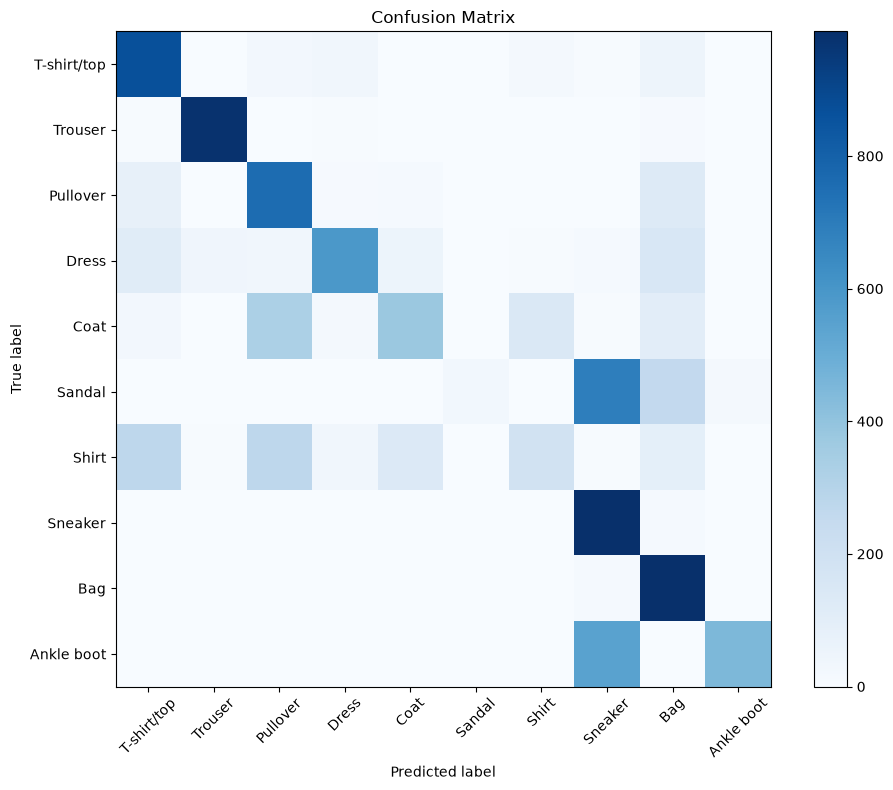

In [28]:
# ------------------------------------------------------------
# 5. Calculate cosine similarities, make predictions, and report accuracy, and confusion matrix
# ------------------------------------------------------------

y_true_A, y_pred_A = [], []

class_embeddings_A = get_text_embeddings_A(improved_prompts)

for pixel_values, labels in test_loader:
    image_embeddings_A = get_image_embeddings_A(pixel_values)

    similarity_A = get_cosine_similarity(
        image_embeddings_A, class_embeddings_A
    )

    predictions_A = get_predictions(similarity_A)

    # Report the accuracy of the predictions
    accuracy_A = accuracy_score(labels.cpu().numpy(), predictions_A)
    print(f"Accuracy: {accuracy_A:.2f}")

    y_true_A.extend(labels.cpu().numpy())
    y_pred_A.extend(predictions_A)

accuracy_all_A = accuracy_score(y_true_A, y_pred_A)
print(f"Overall Accuracy: {accuracy_all_A:.2f}")


# Report the confusion matrix using the function already defined in the assignment
plot_confusion_matrix(y_true_A, y_pred_A, CLASS_NAMES)

In [ ]:
# ------------------------------------------------------------
# 8. Plot confusion matrix
# ------------------------------------------------------------

### Short Report

In this section, you will write a short report summarizing your findings from the mini-experiment. The report should include the following sections:

- **Introduction**: Briefly describe the mini-experiment you conducted and its objectives.
- **Methodology**: Explain the steps you took to conduct the experiment, including any modifications you made to the code or model.
- **Results**: Present the results of your experiment.
- **Discussion**: Reflect on the performance of the model and the implications of your findings. Consider the strengths and weaknesses of zero-shot transformers versus a trained CNN.

# Short Report: Zero-Shot Classification Using an Alternative CLIP Model

## Introduction

For this mini-experiment, I wanted to explore whether using a different and larger CLIP model could improve zero-shot classification on the Fashion-MNIST dataset. In my previous experiments, I first tested the original CLIP model and then improved the text prompts by adding more specific descriptions of the clothing categories. The improved prompts increased the accuracy from 56% to 65%. For this experiment, I decided to try a larger CLIP model called `openai/clip-vit-large-patch14` to see if it could achieve even better results. The main difference between the two CLIP models is their Vision Transformer architecture. The original model uses 32 × 32 pixel patches, while the alternative model uses smaller 14 × 14 pixel patches. The alternative model also has more transformer layers (24 compared to 12). I was interested in testing whether these differences could help the model capture more detailed visual information and improve the classification of similar clothing categories.

## Methodology

I replaced the original CLIP model with a larger version called openai/clip-vit-large-patch14. I used the same improved text prompts from my previous experiment, which included more details about the appearance and features of each clothing category. For example, I described the thick fabric of coats, the knitted appearance of pullovers, and the open-toe design of sandals.

The model generated image and text embeddings, and I calculated the cosine similarity between them. The category with the highest similarity score was selected as the prediction. I used the same Fashion-MNIST test dataset and evaluation setup as in my previous experiment. I also reused the functions from the previous section of the assignment to calculate the accuracy and display the confusion matrix.

The model was evaluated on my CPU, and the full evaluation took approximately 175 minutes to complete.

## Results

The alternative CLIP model achieved an overall accuracy of 62%. This was higher than the original zero-shot baseline accuracy of 56%, but lower than the 65% achieved when I used improved prompts with the original CLIP model.

Since I used the same improved prompts and evaluation setup for both CLIP models, I could compare their results directly. The larger CLIP model performed 3 percentage points lower than the original CLIP model with improved prompts.

The confusion matrix showed that the alternative model could recognize some clothing categories better than others. However, it still had difficulty distinguishing between certain clothing items that looked similar. For example, some coats were confused with pullovers, and some ankle boots were classified as sneakers.

For comparison, the CNN baseline from Assignment 1 achieved 84.34%, while the final trained CNN achieved 89.05%. Both CNN models performed considerably better than the zero-shot CLIP models.

## Discussion

Based on my results, improving the text prompts had a positive effect on the original CLIP model, increasing its accuracy from 56% to 65%. This suggests that more detailed descriptions can help CLIP recognize clothing categories more accurately.

However, when I compared the original CLIP model and the larger CLIP model using the same improved prompts, the original model achieved 65%, while the larger model achieved 62%. I initially expected the larger model to perform better, but the results showed that increasing the model size does not necessarily lead to higher accuracy for every dataset.

The confusion matrix also showed that the alternative model still struggled with clothing categories that had similar appearances. One advantage of zero-shot CLIP is that it can classify images without being trained specifically on the Fashion-MNIST dataset. It is also flexible because its predictions can be influenced by changing the text prompts.

However, the CNN models from Assignment 1 achieved much higher accuracy. I think this is because they were trained specifically to recognize the clothing categories in this dataset. Although CLIP is useful because it does not require task-specific training, it was less accurate for this particular classification task.

Another limitation I noticed was the processing time. The larger CLIP model took approximately 175 minutes to evaluate the test dataset on my CPU. This shows that using a larger model can also require significantly more computing time.

Overall, these experiments helped me understand that prompt engineering can improve zero-shot classification, but using a larger model does not necessarily improve accuracy. For the Fashion-MNIST dataset, the trained CNN models performed much better than the zero-shot CLIP models.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/17/2026`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.